# From Words to Worlds · Re-captioning study with fitted captions (from scratch)

**Praniti Kale** · IE 7615 Deep Learning for AI · Generative project

**Where the pilot left off.** The first re-captioning run compared images generated from three captions of the same 100 test photos: the human COCO caption, a short model caption and a detailed model caption (Florence-2-large). The detailed captions named far more of each photo's objects (80.7% vs 64.5%), yet the images were barely closer to the real photo and did not contain more of its objects. But **94% of the detailed captions were longer than the 77 tokens CLIP can read**, so Stable Diffusion never saw their last 25 tokens on average. The pilot could not tell apart two explanations:

| Explanation | If true, a detailed caption that **fits** in 77 tokens should… |
|---|---|
| **A. The cut-off**: the useful detail was in the part Stable Diffusion never read | do clearly better than the cut-off detailed caption |
| **B. The model**: Stable Diffusion cannot use more detail even when it reads it | do no better than the cut-off detailed caption or the human caption |

**What this notebook adds: a fourth caption, "detailed, fitted".** Each detailed caption is rewritten to fit in 77 tokens, keeping the most informative parts first (Section 5): filler such as "The image shows" is removed, the first sentence (the main subject) is always kept, and the remaining sentences are added in order of how many **new** objects they mention, until the 77-token budget is full. It uses only the caption's own text, never the photo's labels, so it is a fair rewrite anyone could do.

**What this version adds** (from a review of the first results):
1. "Share of the photo's objects named" is also computed **without people**, so it lines up with object recall, which leaves people out.
2. A stricter recall, **named-object recall**: of the objects a caption names *in the part Stable Diffusion reads* (and the photo shows), how many the detector finds. A miss there cannot be blamed on the caption or the token limit.
3. Images the safety checker **blacked out** are found automatically, left out of every average and counted separately.
4. The verdicts say "no detectable difference", not "no difference": with 100 photos and one seed, small effects cannot be ruled out.
5. A list of every **"named, read, but still missing"** object (image id, caption, missing object, seed) is exported for follow-up rescue experiments.

**This version runs from scratch.** It ignores any earlier results on Drive: it captions the 100 photos again with Florence-2, fits the detailed captions, and generates all 400 images (four captions per photo), saving everything to its own folders (`results/recaptioning_scratch/`, `runs/recaptioning_scratch/`) so nothing earlier is overwritten. About **45 minutes** on a T4. To reuse an earlier pilot instead and only make the 100 new images (about 15 minutes), set `FROM_SCRATCH = False` in Section 1. Milestone 1's data rules and splits are rebuilt from the COCO annotations, and only the 100 photos used here are downloaded.

In [1]:
%pip install -q -U diffusers transformers accelerate safetensors

## 1. Setup

In [2]:
import os, sys, re, json, time, random, zipfile, textwrap, warnings
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from PIL import Image
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

CFG = dict(seed_eval=2026, image_size=512, min_short_side=256, n_eval=2000,
           n_recap=100,                       # test photos re-captioned and generated (first rows of eval_2000)
           seeds=(0,),                         # generation seeds per caption
           steps=30, guidance=7.5,
           min_box_kept=0.5, min_cover=0.005,  # an object counts if half its box survives the crop and it is not tiny
           detector_min_score=0.5,
           sd_id="stable-diffusion-v1-5/stable-diffusion-v1-5", clip_id="openai/clip-vit-large-patch14",
           captioners=("florence-community/Florence-2-large", "Salesforce/blip2-opt-2.7b"))
SOURCES = ["human", "model_short", "model_detailed", "model_detailed_fit"]
LABEL = {"human": "Human (COCO)", "model_short": "Model, short", "model_detailed": "Model, detailed (cut at 77)",
         "model_detailed_fit": "Model, detailed, fitted"}
COLORS = ["#888888", "#3b6ea5", "#c06c3e", "#5a8f5a"]

IN_COLAB = "google.colab" in sys.modules
if "W2W_ROOT" in os.environ:
    DATA = RESULTS_ROOT = Path(os.environ["W2W_ROOT"])
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA, RESULTS_ROOT = Path("/content/w2w_data"), Path("/content/drive/MyDrive/w2w_praniti")
else:
    DATA = RESULTS_ROOT = Path.cwd() / "w2w_praniti"
COCO = DATA / "coco"
IMAGES_DIR, ANN_DIR, PROC_DIR = COCO / "val2017", COCO / "annotations", COCO / "val2017_512"
FROM_SCRATCH = True          # True: caption and generate everything again; False: reuse an earlier pilot on Drive
if FROM_SCRATCH:
    PILOT = OUT = RESULTS_ROOT / "results" / "recaptioning_scratch"
    GEN = RESULTS_ROOT / "runs" / "recaptioning_scratch"
else:
    PILOT = RESULTS_ROOT / "results" / "recaptioning"          # the pilot's results, reused
    OUT = RESULTS_ROOT / "results" / "recaptioning_v2"
    GEN = RESULTS_ROOT / "runs" / "recaptioning"
FIGS = OUT / "figures"
for p in (COCO, IMAGES_DIR, PROC_DIR, PILOT, OUT, FIGS, GEN):
    p.mkdir(parents=True, exist_ok=True)


def savefig(name):
    plt.savefig(FIGS / f"{name}.png", bbox_inches="tight", dpi=140)


print("from scratch:", FROM_SCRATCH, "| data:", DATA, "| results:", OUT, "| images:", GEN)

Mounted at /content/drive
from scratch: True | data: /content/w2w_data | results: /content/drive/MyDrive/w2w_praniti/results/recaptioning_scratch | images: /content/drive/MyDrive/w2w_praniti/runs/recaptioning_scratch


## 2. Data: the same 100 test photos as the pilot

Downloads the COCO 2017 annotations, rebuilds the frozen 2,000-pair test split with the Milestone 1 rules (checked against the saved split file if it is on Drive), and takes its first 100 pairs, exactly as the pilot did. Only those 100 photos are downloaded, then center-cropped to 512 × 512 as in Milestone 1.

In [3]:
def download(url, dest):
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    tmp = dest.with_suffix(dest.suffix + ".part")
    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        with open(tmp, "wb") as f, tqdm(total=int(r.headers.get("content-length", 0)), unit="B", unit_scale=True, desc=dest.name) as bar:
            for chunk in r.iter_content(chunk_size=1 << 20):
                f.write(chunk); bar.update(len(chunk))
    tmp.rename(dest)
    return dest


if not (ANN_DIR / "captions_val2017.json").exists() or not (ANN_DIR / "instances_val2017.json").exists():
    with zipfile.ZipFile(download("http://images.cocodataset.org/annotations/annotations_trainval2017.zip",
                                  COCO / "annotations_trainval2017.zip")) as z:
        z.extractall(COCO, [m for m in z.namelist() if m.endswith(("captions_val2017.json", "instances_val2017.json"))])
caps_json = json.load(open(ANN_DIR / "captions_val2017.json", encoding="utf-8"))
inst_json = json.load(open(ANN_DIR / "instances_val2017.json", encoding="utf-8"))

_WS = re.compile(r"\s+")


def clean_caption(text):
    t = _WS.sub(" ", text.replace("\n", " ")).strip()
    return re.sub(r"\s+([.,!?;:])", r"\1", t)


by_image = defaultdict(list)
for a in caps_json["annotations"]:
    by_image[a["image_id"]].append(a["caption"])
rows = []
for im in sorted(caps_json["images"], key=lambda d: d["id"]):
    seen = set()
    for c in by_image.get(im["id"], []):
        cc = clean_caption(c)
        if cc and cc.lower() not in seen:
            seen.add(cc.lower()); rows.append({"image_id": im["id"], "caption": cc})
caps = pd.DataFrame(rows)
caps.insert(0, "caption_idx", range(len(caps)))
images = pd.DataFrame(caps_json["images"]).rename(columns={"id": "image_id"}).set_index("image_id")

eligible = sorted(i for i, r in images.iterrows() if min(r.width, r.height) >= CFG["min_short_side"])
rng = random.Random(CFG["seed_eval"])
rows = []
for iid in rng.sample(eligible, CFG["n_eval"]):
    ci = rng.choice(caps.loc[caps.image_id == iid, "caption_idx"].tolist())
    rows.append({"image_id": iid, "caption_idx": ci, "caption": caps.loc[caps.caption_idx == ci, "caption"].item()})
ev = pd.DataFrame(rows)
saved = RESULTS_ROOT / "results" / "splits" / "eval_2000.csv"
if saved.exists():
    old = pd.read_csv(saved)
    assert old.image_id.tolist() == ev.image_id.tolist() and old.caption_idx.tolist() == ev.caption_idx.tolist()
    print("rebuilt eval_2000 matches the Milestone 1 split file")
sub = ev.head(CFG["n_recap"]).reset_index(drop=True)


def center_square(img, size):
    w, h = img.size
    s = min(w, h); left, top = (w - s) // 2, (h - s) // 2
    return img.crop((left, top, left + s, top + s)).resize((size, size), Image.LANCZOS)


def ensure_png(iid):
    out = PROC_DIR / (Path(images.loc[iid, "file_name"]).stem + ".png")
    if not out.exists():
        src = IMAGES_DIR / images.loc[iid, "file_name"]
        if not src.exists():                                   # download just this photo
            r = requests.get(images.loc[iid, "coco_url"], timeout=60); r.raise_for_status()
            src.write_bytes(r.content)
        with Image.open(src) as im:
            center_square(im.convert("RGB"), CFG["image_size"]).save(out)
    return out


with ThreadPoolExecutor(8) as pool:
    sub["real_path"] = [str(p) for p in pool.map(ensure_png, sub.image_id)]
print(f"{len(sub)} test photos ready, e.g. \"{sub.caption.iloc[0]}\"")

annotations_trainval2017.zip:   0%|          | 0.00/253M [00:00<?, ?B/s]

rebuilt eval_2000 matches the Milestone 1 split file
100 test photos ready, e.g. "A group of people, mostly children, are gathering around a tent."


## 3. Which objects each photo shows, and which each caption names

The Milestone 1 rules, unchanged: a caption word is mapped to the COCO object type it names (plurals, people words, synonyms, two-word names; unclear words such as *orange* or *mouse* left out), and a photo's object counts only if at least half its box survives the crop and the kept part is not tiny. COCO labels only 80 object types and misses some objects, so "named but not labelled" does not always mean the caption is wrong.

In [4]:
COCO_CLASSES = [c["name"] for c in sorted(inst_json["categories"], key=lambda c: c["id"])]
SYNONYMS = {
    "bike": "bicycle", "motorbike": "motorcycle", "moped": "motorcycle", "scooter": "motorcycle",
    "plane": "airplane", "jet": "airplane", "aircraft": "airplane", "airliner": "airplane",
    "taxi": "car", "sedan": "car", "suv": "car", "sailboat": "boat", "ship": "boat", "canoe": "boat",
    "kayak": "boat", "yacht": "boat", "ferry": "boat", "stoplight": "traffic light", "hydrant": "fire hydrant",
    "puppy": "dog", "kitten": "cat", "kitty": "cat", "pony": "horse", "lamb": "sheep", "cattle": "cow",
    "bull": "cow", "pigeon": "bird", "seagull": "bird", "gull": "bird", "duck": "bird", "goose": "bird",
    "parrot": "bird", "swan": "bird", "teddy": "teddy bear",
    "necktie": "tie", "luggage": "suitcase", "purse": "handbag", "racket": "tennis racket",
    "racquet": "tennis racket", "mitt": "baseball glove", "bat": "baseball bat", "glove": "baseball glove",
    "ski": "skis", "surf board": "surfboard", "skate board": "skateboard", "soccer ball": "sports ball",
    "tennis ball": "sports ball", "baseball": "sports ball", "football": "sports ball",
    "basketball": "sports ball", "ball": "sports ball",
    "mug": "cup", "doughnut": "donut", "hotdog": "hot dog", "stove": "oven", "fridge": "refrigerator",
    "plant": "potted plant", "houseplant": "potted plant", "table": "dining table",
    "sofa": "couch", "television": "tv", "monitor": "tv", "phone": "cell phone", "cellphone": "cell phone",
    "smartphone": "cell phone", "remote control": "remote", "controller": "remote",
    "hairdryer": "hair drier", "hair dryer": "hair drier", "blow dryer": "hair drier",
}
PERSON_WORDS = {
    "person", "man", "woman", "people", "boy", "girl", "child", "kid", "guy", "lady", "baby", "toddler",
    "adult", "player", "skier", "surfer", "skateboarder", "snowboarder", "rider", "biker", "cyclist",
    "chef", "cook", "batter", "pitcher", "catcher", "umpire", "crowd", "someone", "gentleman",
    "teenager", "teen", "student", "worker", "officer", "policeman", "soldier", "couple", "family",
    "friend", "mother", "father", "son", "daughter", "he", "she",
}
AMBIGUOUS = {"orange", "mouse", "tie", "glass", "keyboard", "bat", "glove", "table", "plant", "ball",
             "baseball", "football", "bull", "ski", "controller", "monitor"}
IRREGULAR = {"men": "man", "women": "woman", "children": "child", "people": "people", "knives": "knife",
             "mice": "mouse", "geese": "goose", "skis": "skis", "scissors": "scissors", "sheep": "sheep",
             "cattle": "cattle", "glasses": "glass", "buses": "bus", "benches": "bench",
             "sandwiches": "sandwich", "couches": "couch", "ladies": "lady", "babies": "baby",
             "puppies": "puppy", "kitties": "kitty", "ponies": "pony", "teddies": "teddy", "guys": "guy"}
NOT_ADJECTIVE_AFTER = {"", "and", "or", "on", "in", "with", "of", "next", "near", "by", "at", "is", "are",
                       "sitting", "slices", "slice", "juice", "halves", "peel", "tree", "trees"}
STOPWORDS = {"a", "an", "the", "of", "on", "in", "at", "to", "with", "and", "is", "are", "its", "it", "for",
             "by", "some", "very", "while", "into", "that", "this", "there", "his", "her", "their", "from",
             "next", "up", "down", "near", "over", "through", "each", "other", "around", "another", "be",
             "being", "has", "have"}
_CLASSES = set(COCO_CLASSES)
_TERMS = _CLASSES | set(SYNONYMS) | PERSON_WORDS


def words_of(caption):
    out = [w.strip(".,!?;:'\"()[]").lower() for w in caption.split()]
    return [re.sub(r"'s$", "", w) for w in out if w]


def singular(w):
    if w in IRREGULAR:
        return IRREGULAR[w]
    if w in _TERMS:
        return w
    if w.endswith("ies") and w[:-3] + "y" in _TERMS:
        return w[:-3] + "y"
    if w.endswith("es") and w[:-2] in _TERMS:
        return w[:-2]
    if w.endswith("s") and w[:-1] in _TERMS:
        return w[:-1]
    return w


def to_category(term):
    if term in _CLASSES:
        return term
    if term in PERSON_WORDS:
        return "person"
    return SYNONYMS.get(term)


def named_categories(caption):
    # COCO categories the caption names, in caption order, one entry per category
    raw = words_of(caption)
    sing = [singular(w) for w in raw]
    found, i = {}, 0
    while i < len(sing):
        hit = None
        if i + 1 < len(sing):
            cat = to_category(f"{raw[i]} {sing[i + 1]}")
            if cat:
                hit = (cat, raw[i:i + 2], False, 2)
        if hit is None:
            cat = to_category(sing[i])
            if cat:
                if raw[i] == "orange" and (raw[i + 1] if i + 1 < len(raw) else "") not in NOT_ADJECTIVE_AFTER:
                    i += 1                          # "an orange cat": a colour
                    continue
                hit = (cat, raw[i:i + 1], sing[i] in AMBIGUOUS or raw[i] in AMBIGUOUS, 1)
        if hit:
            cat, ws, amb, span = hit
            if cat not in found:
                found[cat] = {"category": cat, "words": " ".join(ws), "start": i, "ambiguous": amb}
            elif found[cat]["ambiguous"] and not amb:
                found[cat]["ambiguous"] = False
            i += span
        else:
            i += 1
    return sorted(found.values(), key=lambda d: d["start"])


def cats_of(c):
    return [n["category"] for n in named_categories(c)]


# checks on the rules before using them
assert len(_CLASSES) == 80
assert cats_of("A teddy bear sitting on a bed.") == ["teddy bear", "bed"]
assert cats_of("Two hot dogs on a plate") == ["hot dog"]
assert cats_of("Two men riding bikes past some buses.") == ["person", "bicycle", "bus"]
assert cats_of("A puppy and a kitten on a sofa") == ["dog", "cat", "couch"]
assert cats_of("An orange cat on a couch") == ["cat", "couch"]
assert named_categories("An orange and a banana")[0]["ambiguous"]
print("mapping rules: all checks passed")

mapping rules: all checks passed


In [5]:
def crop_box(w, h):
    s = min(w, h); left, top = (w - s) // 2, (h - s) // 2
    return left, top, left + s, top + s


def box_kept(bbox, w, h):
    x, y, bw, bh = bbox
    cx0, cy0, cx1, cy1 = crop_box(w, h)
    ix = max(0.0, min(x + bw, cx1) - max(x, cx0)); iy = max(0.0, min(y + bh, cy1) - max(y, cy0))
    s = min(w, h)
    return (ix * iy / (bw * bh) if bw * bh > 0 else 0.0), ix * iy / (s * s)


CAT_NAME = {c["id"]: c["name"] for c in inst_json["categories"]}
PHOTO_OBJS, ALL_OBJS = defaultdict(set), defaultdict(set)     # visible after the crop / labelled anywhere
SUB_IDS = set(sub.image_id)
for a in inst_json["annotations"]:
    iid = a["image_id"]
    if iid not in SUB_IDS:
        continue
    name = CAT_NAME[a["category_id"]]
    ALL_OBJS[iid].add(name)
    kept, cover = box_kept(a["bbox"], images.loc[iid, "width"], images.loc[iid, "height"])
    if kept >= CFG["min_box_kept"] and cover >= CFG["min_cover"]:
        PHOTO_OBJS[iid].add(name)


def named_objects(text):
    return {n["category"] for n in named_categories(text) if not n["ambiguous"]}


def mention_stats(text, iid):
    named, visible = named_objects(text), PHOTO_OBJS[iid]
    named_np, visible_np = named - {"person"}, visible - {"person"}
    return {"objects_named": len(named),
            "share_of_photo_objects_named": len(named & visible) / len(visible) if visible else np.nan,
            # the same share with people left out on both sides, to line up with object recall
            "share_of_photo_objects_named_no_person": len(named_np & visible_np) / len(visible_np) if visible_np else np.nan,
            "share_named_not_labelled": len(named - ALL_OBJS[iid]) / len(named) if named else np.nan}


def named_and_visible(text, iid):
    # objects the text names that the photo shows after the crop, person excluded
    return (named_objects(text) & PHOTO_OBJS[iid]) - {"person"}


n_obj = pd.Series([len(PHOTO_OBJS[i]) for i in sub.image_id])
print(f"photos with at least one visible labelled object: {(n_obj > 0).sum()} of {len(sub)}; "
      f"median {n_obj.median():.0f} object types per photo")

photos with at least one visible labelled object: 98 of 100; median 2 object types per photo


## 4. Re-captioning the photos

Each cropped test photo gets a **short** and a **detailed** caption from the captioning model. Decoding is deterministic (beam search, no sampling), so rerunning gives the same captions. From scratch, every photo is captioned again and the captions are saved; a rerun of this notebook reuses them. With `FROM_SCRATCH = False`, the earlier pilot's captions are reused instead.

In [6]:
import torch
import torch.nn.functional as F
from transformers import AutoProcessor

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
assert DEVICE == "cuda", "This notebook needs a GPU (Colab: Runtime -> Change runtime type -> T4 GPU)"
print(torch.__version__, torch.cuda.get_device_name(0))


def load_captioner():
    errors = []
    try:                                                    # Florence-2, built into recent transformers
        from transformers import Florence2ForConditionalGeneration
        mid = CFG["captioners"][0]
        proc = AutoProcessor.from_pretrained(mid)
        model = Florence2ForConditionalGeneration.from_pretrained(mid, torch_dtype=DTYPE).to(DEVICE).eval()

        @torch.no_grad()
        def run(img, task):
            inputs = proc(text=task, images=img, return_tensors="pt").to(DEVICE, DTYPE)
            ids = model.generate(**inputs, max_new_tokens=256, num_beams=3, do_sample=False)
            raw = proc.batch_decode(ids, skip_special_tokens=False)[0]
            try:
                parsed = proc.post_process_generation(raw, task=task, image_size=img.size)
                text = parsed.get(task, parsed) if isinstance(parsed, dict) else parsed
            except Exception:
                text = proc.batch_decode(ids, skip_special_tokens=True)[0]
            return re.sub(r"<[^>]+>", "", str(text)).strip()

        return "Florence-2-large", model, lambda img: (run(img, "<CAPTION>"), run(img, "<MORE_DETAILED_CAPTION>"))
    except Exception as e:
        errors.append(f"Florence-2: {type(e).__name__}: {str(e)[:200]}")
    try:                                                    # fallback: BLIP-2
        from transformers import Blip2ForConditionalGeneration, Blip2Processor
        mid = CFG["captioners"][1]
        proc = Blip2Processor.from_pretrained(mid)
        model = Blip2ForConditionalGeneration.from_pretrained(mid, torch_dtype=DTYPE).to(DEVICE).eval()

        @torch.no_grad()
        def run(img, prompt, n):
            inputs = proc(images=img, text=prompt, return_tensors="pt").to(DEVICE, DTYPE) if prompt else \
                proc(images=img, return_tensors="pt").to(DEVICE, DTYPE)
            ids = model.generate(**inputs, max_new_tokens=n, num_beams=3, do_sample=False, repetition_penalty=1.3)
            text = proc.batch_decode(ids, skip_special_tokens=True)[0].strip()
            return text[len(prompt):].strip() if prompt and text.startswith(prompt) else text

        return "BLIP-2 OPT-2.7B", model, lambda img: (run(img, None, 30),
                                                      run(img, "Question: Describe this image in detail. Answer:", 90))
    except Exception as e:
        errors.append(f"BLIP-2: {type(e).__name__}: {str(e)[:200]}")
    raise RuntimeError("no captioning model could be loaded:\n" + "\n".join(errors))


cap_file = PILOT / "captions.csv"
if cap_file.exists() and set(pd.read_csv(cap_file).caption_idx) == set(sub.caption_idx):
    capdf = pd.read_csv(cap_file)
    CAPTIONER = capdf.captioner.iloc[0]
    print(f"reusing saved captions ({CAPTIONER}) from {cap_file}")
else:
    CAPTIONER, cap_model, caption = load_captioner()
    print("captioning model:", CAPTIONER)
    rows, t0 = [], time.perf_counter()
    for r in tqdm(sub.itertuples(), total=len(sub), desc="captioning"):
        short, detailed = caption(Image.open(r.real_path).convert("RGB"))
        rows.append({"image_id": r.image_id, "caption_idx": r.caption_idx, "human": r.caption,
                     "model_short": short, "model_detailed": detailed, "captioner": CAPTIONER})
    capdf = pd.DataFrame(rows)
    capdf.to_csv(cap_file, index=False)
    print(f"captioned {len(capdf)} photos in {time.perf_counter() - t0:.0f} s")
    del cap_model; torch.cuda.empty_cache()
sub = sub.merge(capdf[["caption_idx", "model_short", "model_detailed"]], on="caption_idx").rename(columns={"caption": "human"})
for r in sub.head(3).itertuples():
    print(f"\nhuman   : {r.human}\nshort   : {r.model_short}\ndetailed: {textwrap.shorten(r.model_detailed, 300)}")

2.11.0+cu130 Tesla T4
reusing saved captions (Florence-2-large) from /content/drive/MyDrive/w2w_praniti/results/recaptioning_scratch/captions.csv

human   : A group of people, mostly children, are gathering around a tent.
short   : A group of people walking through a park with children.
detailed: The image shows a group of people walking in a park. There are several children and adults in the image, some of whom are holding stuffed animals. The children are walking on a grassy area with trees and bushes in the background. There is a green tent set up on the right side of the image and [...]

human   : An organized baseball match between two teams with the batter swinging
short   : A baseball player swinging a bat on top of a field.
detailed: The image shows a baseball game in progress. The batter is at home plate and is in the process of swinging his bat. He is wearing a black jersey with the number 21 on it and a black helmet. The catcher is crouched behind home plate, ready to catch 

## 5. The fourth caption: detailed, fitted to 77 tokens

Stable Diffusion's CLIP reads 77 tokens, two of which are the start and end markers, so a caption has **75 tokens** of room. Each detailed caption is rewritten to fit, using only its own text:

1. **Split** it into sentences.
2. **Remove filler** at the start of a sentence ("The image shows", "This picture depicts", "In the image,") that tells the model nothing about the scene.
3. **Always keep the first sentence**: it names the main subject. If it alone is too long, it is cut at a word boundary.
4. **Add the other sentences greedily**: at each step, the sentence that names the most COCO objects **not yet mentioned** (using the Section 3 word table; ties go to the earlier sentence), as long as it still fits. Sentences that add no new object (often background, lighting, mood) come last and are the first to be left out.
5. **Put the kept sentences back in their original order**, so the text still reads naturally.

The cut-off detailed caption keeps whatever happens to come first; the fitted one keeps what names the most of the scene. Comparing them shows whether the cut-off was what held the detailed captions back.

In [7]:
from transformers import CLIPTokenizer

clip_tok = CLIPTokenizer.from_pretrained(CFG["clip_id"])
BUDGET = 75                                                  # 77 minus the start and end markers
_FILLER = re.compile(r"^(?:in\s+)?(?:the|this)\s+(?:image|photo|picture|scene)\s*(?:shows|depicts|features|captures|contains|is of)?\s*,?\s*", re.I)
_SENT = re.compile(r"(?<=[.!?])\s+")


def n_tokens(text):
    return len(clip_tok(text, add_special_tokens=False)["input_ids"])


def strip_filler(sentence):
    out = _FILLER.sub("", sentence.strip())
    return out[:1].upper() + out[1:] if out else out


def objects_in(text):
    return {n["category"] for n in named_categories(text) if not n["ambiguous"]}


def cut_to_budget(text, budget, count=n_tokens):
    words = text.split()
    while words and count(" ".join(words)) > budget:
        words.pop()
    return " ".join(words)


def fit_caption(text, budget=BUDGET, count=n_tokens):
    sents = [strip_filler(s) for s in _SENT.split(text.strip()) if s.strip()]
    sents = [s for s in sents if s]
    if not sents:
        return cut_to_budget(text, budget, count), {"sentences": 0, "kept": 0}
    if count(sents[0]) > budget:
        return cut_to_budget(sents[0], budget, count), {"sentences": len(sents), "kept": 1}
    keep, seen = [0], set(objects_in(sents[0]))
    left = list(range(1, len(sents)))
    while left:
        gain = {i: len(objects_in(sents[i]) - seen) for i in left}
        for i in sorted(left, key=lambda i: (-gain[i], i)):
            trial = " ".join(sents[j] for j in sorted(keep + [i]))
            if count(trial) <= budget:
                keep.append(i); seen |= objects_in(sents[i]); left.remove(i)
                break
        else:
            break                                                # nothing else fits
    return " ".join(sents[j] for j in sorted(keep)), {"sentences": len(sents), "kept": len(keep)}


# checks on a word-count stand-in for the tokenizer
wc = lambda t: len(t.split())
demo = ("The image shows a dog on a bench. The sky is blue and calm. There is a red car and a bus behind it. "
        "A cat sits nearby on the grass.")
fitted, info = fit_caption(demo, budget=20, count=wc)
assert fitted.startswith("A dog on a bench.") and "car" in fitted and "The image shows" not in fitted, fitted
assert wc(fitted) <= 20 and "sky" not in fitted                 # the sentence with no new object is dropped first
assert fit_caption("The image shows a very long sentence " * 10, budget=8, count=wc)[0].count(" ") <= 7

rows = []
for r in sub.itertuples():
    fitted, info = fit_caption(r.model_detailed)
    rows.append({"caption_idx": r.caption_idx, "model_detailed_fit": fitted,
                 "sentences": info["sentences"], "sentences_kept": info["kept"]})
fit_df = pd.DataFrame(rows)
sub = sub.drop(columns=["model_detailed_fit", "sentences", "sentences_kept"], errors="ignore").merge(fit_df, on="caption_idx")
assert (sub.model_detailed_fit.map(n_tokens) <= BUDGET).all()
sub[["image_id", "caption_idx", "human", "model_short", "model_detailed", "model_detailed_fit"]].to_csv(OUT / "captions_v2.csv", index=False)
print(f"fitted {len(sub)} captions: on average {sub.sentences_kept.mean():.1f} of {sub.sentences.mean():.1f} sentences kept, "
      f"{sub.model_detailed_fit.map(n_tokens).mean():.0f} tokens (budget {BUDGET})")
for r in sub.head(2).itertuples():
    print(f"\ndetailed: {textwrap.shorten(r.model_detailed, 400)}\nfitted  : {r.model_detailed_fit}")

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (84 > 77). Running this sequence through the model will result in indexing errors


fitted 100 captions: on average 4.1 of 5.7 sentences kept, 69 tokens (budget 75)

detailed: The image shows a group of people walking in a park. There are several children and adults in the image, some of whom are holding stuffed animals. The children are walking on a grassy area with trees and bushes in the background. There is a green tent set up on the right side of the image and a few people sitting on benches on the left side. The sky is overcast and the overall atmosphere [...]
fitted  : A group of people walking in a park. There are several children and adults in the image, some of whom are holding stuffed animals. The children are walking on a grassy area with trees and bushes in the background. There is a green tent set up on the right side of the image and a few people sitting on benches on the left side.

detailed: The image shows a baseball game in progress. The batter is at home plate and is in the process of swinging his bat. He is wearing a black jersey with the number 2

## 6. How the captions differ

As in the pilot, plus one new column, **objects named in the part Stable Diffusion reads**: the same count, but only over the first 75 tokens of each caption, which is all the model ever sees. It is the fairest measure of how much each caption actually tells the model.

,words,clip_tokens,over_77_share,tokens_cut_mean,objects_named,photo_objects_named,photo_objects_named_readable,photo_objects_named_no_person,photo_objects_named_readable_no_person,named_not_labelled
Human (COCO),10.0,13.0,0.00,0.00,1.26,0.645,0.645,0.547,0.547,0.042
"Model, short",11.0,14.0,0.00,0.00,1.43,0.692,0.692,0.621,0.621,0.053
"Model, detailed (cut at 77)",84.0,96.5,0.94,25.19,1.87,0.807,0.777,0.747,0.715,0.082
"Model, detailed, fitted",61.0,71.5,0.00,0.00,1.87,0.807,0.807,0.747,0.747,0.082


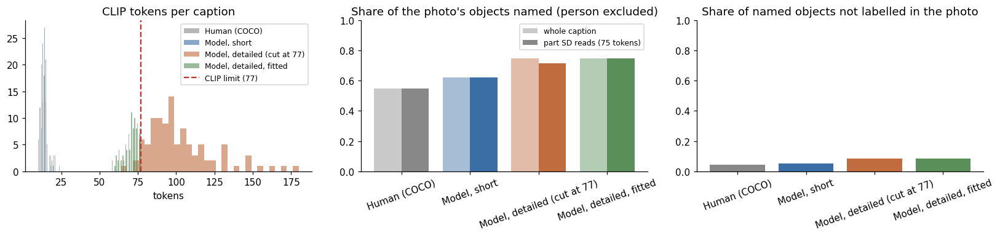

In [8]:
def readable_part(text):
    # the text Stable Diffusion actually reads: the first 75 tokens
    ids = clip_tok(text, add_special_tokens=False)["input_ids"][:BUDGET]
    return clip_tok.decode(ids)


stats = []
for r in sub.itertuples():
    for s in SOURCES:
        text = getattr(r, s)
        n_tok = len(clip_tok(text)["input_ids"])
        stats.append({"image_id": r.image_id, "source": s, "words": len(text.split()), "clip_tokens": n_tok,
                      "over_77": n_tok > 77, "tokens_cut": max(0, n_tok - 77), **mention_stats(text, r.image_id),
                      "photo_objects_named_in_readable_part": mention_stats(readable_part(text), r.image_id)["share_of_photo_objects_named"],
                      "photo_objects_named_in_readable_part_no_person":
                          mention_stats(readable_part(text), r.image_id)["share_of_photo_objects_named_no_person"]})
stats = pd.DataFrame(stats)
cap_table = stats.groupby("source").agg(words=("words", "median"), clip_tokens=("clip_tokens", "median"),
                                        over_77_share=("over_77", "mean"), tokens_cut_mean=("tokens_cut", "mean"),
                                        objects_named=("objects_named", "mean"),
                                        photo_objects_named=("share_of_photo_objects_named", "mean"),
                                        photo_objects_named_readable=("photo_objects_named_in_readable_part", "mean"),
                                        photo_objects_named_no_person=("share_of_photo_objects_named_no_person", "mean"),
                                        photo_objects_named_readable_no_person=("photo_objects_named_in_readable_part_no_person", "mean"),
                                        named_not_labelled=("share_named_not_labelled", "mean")).loc[SOURCES]
cap_table.index = [LABEL[s] for s in cap_table.index]
cap_table.to_csv(OUT / "caption_stats.csv")
display(cap_table.round(3))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for s, c in zip(SOURCES, COLORS):
    ax[0].hist(stats[stats.source == s].clip_tokens, bins=30, alpha=0.6, label=LABEL[s], color=c)
ax[0].axvline(77, color="#b33", ls="--", label="CLIP limit (77)"); ax[0].set(title="CLIP tokens per caption", xlabel="tokens"); ax[0].legend(fontsize=8)
xs = np.arange(len(SOURCES))
ax[1].bar(xs - 0.2, cap_table.photo_objects_named_no_person, 0.4, color=COLORS, alpha=0.45, label="whole caption")
ax[1].bar(xs + 0.2, cap_table.photo_objects_named_readable_no_person, 0.4, color=COLORS, label="part SD reads (75 tokens)")
ax[1].set_xticks(xs); ax[1].set_xticklabels(cap_table.index)
ax[1].set(title="Share of the photo's objects named (person excluded)", ylim=(0, 1)); ax[1].legend(fontsize=8)
ax[2].bar(cap_table.index, cap_table.named_not_labelled, color=COLORS)
ax[2].set(title="Share of named objects not labelled in the photo", ylim=(0, 1))
for a in ax[1:]:
    a.tick_params(axis="x", rotation=20)
plt.tight_layout(); savefig("01_caption_stats"); plt.show()

## 7. Generating images from each caption

Stable Diffusion 1.5 with its defaults (PNDM, 30 steps, guidance 7.5), **the same seed for all four captions of a photo**, so the only difference between the images is the text. From scratch all 400 images are generated; images already in the output folder (from an interrupted run) are skipped, so a Colab disconnect costs nothing. Captions longer than 77 CLIP tokens are cut at 77 by the pipeline, exactly as any user's long prompt would be.

In [9]:
from diffusers import StableDiffusionPipeline

pipe = StableDiffusionPipeline.from_pretrained(CFG["sd_id"], torch_dtype=DTYPE).to(DEVICE)
pipe.set_progress_bar_config(disable=True)
import logging; logging.getLogger("diffusers").setLevel(logging.ERROR)     # silence the truncation warning


@torch.no_grad()
def paint(prompt, seed):
    g = torch.Generator(DEVICE).manual_seed(int(seed))
    out = pipe(prompt, num_inference_steps=CFG["steps"], guidance_scale=CFG["guidance"], generator=g)
    flags = getattr(out, "nsfw_content_detected", None)
    return out.images[0], bool(flags[0]) if flags is not None else False


gen_rows, t0, reused = [], time.perf_counter(), 0
todo = [(r, s, seed) for r in sub.itertuples() for s in SOURCES for seed in CFG["seeds"]]
for r, s, seed in tqdm(todo, desc="generating"):
    path = GEN / s / f"{r.caption_idx}_s{seed}.png"
    path.parent.mkdir(parents=True, exist_ok=True)
    flag = False
    if path.exists():
        reused += 1
    else:
        img, flag = paint(getattr(r, s), seed)
        img.save(path)
    gen_rows.append({"image_id": r.image_id, "caption_idx": r.caption_idx, "source": s, "seed": seed,
                     "path": str(path), "flagged": flag})
gen = pd.DataFrame(gen_rows)
gen.to_csv(OUT / "generated_index.csv", index=False)
print(f"{len(gen)} images: {reused} already on disk, {len(gen) - reused} new ({time.perf_counter() - t0:.0f} s); "
      f"newly safety-flagged: {gen.groupby('source').flagged.sum().to_dict()}")
del pipe; torch.cuda.empty_cache()

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

generating:   0%|          | 0/400 [00:00<?, ?it/s]

400 images: 400 already on disk, 0 new (2 s); newly safety-flagged: {'human': 0, 'model_detailed': 0, 'model_detailed_fit': 0, 'model_short': 0}


## 8. Are the images closer to the real scene?

* **CLIP-I** (higher is better): cosine similarity between the CLIP image embeddings of the generated image and the real photo. It judges the image against the scene, not against the prompt, so all three caption sources are judged the same way.
* **CLIPScore with its own prompt** and **with the human caption**, 100 × cosine, CLIP ViT-L/14.
* **Object recall**: the share of the photo's visible labelled objects (person excluded, reported separately) that a Faster R-CNN detector finds in the generated image. The same detector on the **real** photos gives its own ceiling, since it misses some objects that are really there.

* **Named-object recall** (new, the strictest test of the model): only the objects the caption **names in the part Stable Diffusion reads** and the photo shows (person excluded). If one of these is missing, the caption asked for it and the model read the request, so the miss is the model's.
* Images the safety checker **blacked out** are detected (an all-black image), left out of every average and counted separately.

Differences come with paired bootstrap 95% intervals over photos, both **against the human caption** and, the key test, **fitted against cut-off detailed**.

In [10]:
from transformers import CLIPModel, CLIPProcessor
from torchvision.models.detection import FasterRCNN_ResNet50_FPN_V2_Weights, fasterrcnn_resnet50_fpn_v2

clip_model = CLIPModel.from_pretrained(CFG["clip_id"], torch_dtype=DTYPE).to(DEVICE).eval()
clip_proc = CLIPProcessor.from_pretrained(CFG["clip_id"])


@torch.no_grad()
def clip_images(paths, batch=32):
    out = []
    for i in range(0, len(paths), batch):
        px = clip_proc.image_processor(images=[Image.open(p).convert("RGB") for p in paths[i:i + batch]],
                                       return_tensors="pt")["pixel_values"].to(DEVICE, DTYPE)
        out.append(F.normalize(clip_model.visual_projection(clip_model.vision_model(pixel_values=px).pooler_output).float(), dim=-1).cpu().numpy())
    return np.concatenate(out)


@torch.no_grad()
def clip_texts(texts, batch=64):
    out = []
    for i in range(0, len(texts), batch):
        tok = clip_proc.tokenizer(list(texts[i:i + batch]), padding="max_length", max_length=77, truncation=True,
                                  return_tensors="pt").to(DEVICE)
        out.append(F.normalize(clip_model.text_projection(clip_model.text_model(input_ids=tok.input_ids).pooler_output).float(), dim=-1).cpu().numpy())
    return np.concatenate(out)


weights = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
detector = fasterrcnn_resnet50_fpn_v2(weights=weights).eval().to(DEVICE)
DET_NAMES = weights.meta["categories"]


@torch.no_grad()
def detect(path):
    x = torch.from_numpy(np.asarray(Image.open(path).convert("RGB"), dtype=np.float32) / 255).permute(2, 0, 1)
    r = detector([x.to(DEVICE)])[0]
    return {DET_NAMES[l] for l, s in zip(r["labels"].tolist(), r["scores"].tolist()) if s >= CFG["detector_min_score"]}


def recall(found, iid):
    want = PHOTO_OBJS[iid] - {"person"}
    return len(found & want) / len(want) if want else np.nan


# real photos: CLIP features, and the detector's own ceiling
real_feat = dict(zip(sub.image_id, clip_images(sub.real_path.tolist())))
real_found = {r.image_id: detect(r.real_path) for r in tqdm(sub.itertuples(), total=len(sub), desc="detector on real photos")}
detector_ceiling = float(np.nanmean([recall(real_found[i], i) for i in sub.image_id]))
person_photos = {i for i in sub.image_id if "person" in PHOTO_OBJS[i]}

gfeat = clip_images(gen.path.tolist())
human_by_id = dict(zip(sub.caption_idx, sub.human))
prompt_text = [getattr(sub.set_index("caption_idx").loc[ci], s) for ci, s in zip(gen.caption_idx, gen.source)]
own_t, human_t = clip_texts(prompt_text), clip_texts([human_by_id[ci] for ci in gen.caption_idx])
gen["clip_i"] = [(f * real_feat[i]).sum() for f, i in zip(gfeat, gen.image_id)]
gen["clipscore_own"] = 100 * np.clip((gfeat * own_t).sum(1), 0, None)
gen["clipscore_human"] = 100 * np.clip((gfeat * human_t).sum(1), 0, None)
found = [detect(p) for p in tqdm(gen.path, desc="detector on generated")]
gen["object_recall"] = [recall(f, i) for f, i in zip(found, gen.image_id)]
gen["person_drawn"] = [float("person" in f) if i in person_photos else np.nan for f, i in zip(found, gen.image_id)]

# named-object recall: objects named in the part SD reads that the photo shows (person excluded)
text_by = sub.set_index("caption_idx")
gen["prompt"] = prompt_text
gen["named_read"] = [named_and_visible(readable_part(t), i) for t, i in zip(prompt_text, gen.image_id)]
gen["found"] = found
gen["named_recall"] = [len(f & nr) / len(nr) if nr else np.nan for f, nr in zip(found, gen.named_read)]

# images the safety checker blacked out: all-black, left out of every average
gen["blacked_out"] = [np.asarray(Image.open(p).convert("L")).max() < 10 for p in gen.path]
SCORE_COLS = ["clip_i", "clipscore_own", "clipscore_human", "object_recall", "person_drawn", "named_recall"]
gen.loc[gen.blacked_out, SCORE_COLS] = np.nan
blacked = gen[gen.blacked_out]
print("blacked-out images (left out of every average):", blacked.groupby("source").size().reindex(SOURCES, fill_value=0).to_dict())
if len(blacked):
    display(blacked[["image_id", "caption_idx", "source", "seed"]])

save = gen.drop(columns=["named_read", "found"]).assign(
    named_read=[";".join(sorted(x)) for x in gen.named_read], found=[";".join(sorted(x)) for x in gen.found])
save.to_csv(OUT / "generated_scores.csv", index=False)
print(f"detector recall on the REAL photos (its ceiling): {detector_ceiling:.3f}")

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


... (2 outputs left out)

detector on generated:   0%|          | 0/400 [00:00<?, ?it/s]

blacked-out images (left out of every average): {'human': 1, 'model_short': 1, 'model_detailed': 1, 'model_detailed_fit': 1}


,image_id,caption_idx,source,seed
100,377814,16395,human,0
102,377814,16395,model_detailed,0
103,377814,16395,model_detailed_fit,0
297,460929,19919,model_short,0


detector recall on the REAL photos (its ceiling): 0.915


,clip_i,clipscore_own,clipscore_human,object_recall,person_drawn,named_recall
Human (COCO),0.704,26.353,26.353,0.677,0.941,0.885
"Model, short",0.709,26.371,22.217,0.677,0.882,0.880
"Model, detailed (cut at 77)",0.716,27.025,21.864,0.626,0.902,0.763
"Model, detailed, fitted",0.718,27.182,22.306,0.659,0.922,0.720


,comparison,metric,difference,ci95_low,ci95_high,photos
0,"Model, short vs Human (COCO)",CLIP-I: similarity to the real photo,0.004,-0.010,0.018,98
1,"Model, short vs Human (COCO)","CLIPScore, own prompt",0.113,-0.572,0.758,98
2,"Model, short vs Human (COCO)","CLIPScore, human caption",-4.068,-4.993,-3.165,98
3,"Model, short vs Human (COCO)",Object recall (not person),-0.005,-0.083,0.072,92
4,"Model, short vs Human (COCO)","Person drawn, when the photo has one",-0.059,-0.137,0.000,51
5,"Model, short vs Human (COCO)","Named-object recall (named and read, not person)",-0.009,-0.082,0.064,55
6,"Model, detailed (cut at 77) vs Human (COCO)",CLIP-I: similarity to the real photo,0.012,-0.002,0.027,99
7,"Model, detailed (cut at 77) vs Human (COCO)","CLIPScore, own prompt",0.672,-0.089,1.397,99
8,"Model, detailed (cut at 77) vs Human (COCO)","CLIPScore, human caption",-4.489,-5.354,-3.606,99
9,"Model, detailed (cut at 77) vs Human (COCO)",Object recall (not person),-0.051,-0.142,0.039,93


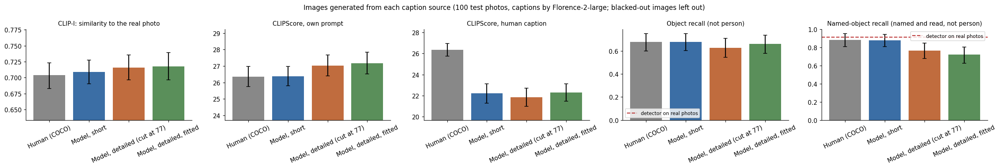

In [11]:
def paired_ci(a, b, n=5000, seed=0):
    d = np.asarray(b, float) - np.asarray(a, float)
    d = d[~np.isnan(d)]
    boots = np.random.default_rng(seed).choice(d, (n, len(d)), replace=True).mean(1)
    return float(d.mean()), float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5)), int(len(d))


METRICS = {"clip_i": "CLIP-I: similarity to the real photo", "clipscore_own": "CLIPScore, own prompt",
           "clipscore_human": "CLIPScore, human caption", "object_recall": "Object recall (not person)",
           "person_drawn": "Person drawn, when the photo has one",
           "named_recall": "Named-object recall (named and read, not person)"}
per_photo = gen.groupby(["source", "image_id"])[list(METRICS)].mean()           # average over seeds
table, deltas = {}, {}
COMPARISONS = [("human", s) for s in SOURCES[1:]] + [("model_detailed", "model_detailed_fit")]
for s in SOURCES:
    table[LABEL[s]] = per_photo.loc[s].mean()
for base, s in COMPARISONS:
    for m in METRICS:
        a = per_photo.loc[base][m].reindex(sub.image_id); b = per_photo.loc[s][m].reindex(sub.image_id)
        deltas[(f"{LABEL[s]} vs {LABEL[base]}", m)] = paired_ci(a.values, b.values)
table = pd.DataFrame(table).T[list(METRICS)]
table.to_csv(OUT / "image_metrics.csv")
display(table.round(3))
delta_df = pd.DataFrame([{"comparison": s, "metric": METRICS[m], "difference": v[0], "ci95_low": v[1], "ci95_high": v[2], "photos": v[3]}
                         for (s, m), v in deltas.items()])
delta_df.to_csv(OUT / "differences.csv", index=False)
display(delta_df.round(3))

fig, ax = plt.subplots(1, 5, figsize=(23, 3.9))
cols = COLORS
for a, m in zip(ax, ["clip_i", "clipscore_own", "clipscore_human", "object_recall", "named_recall"]):
    vals = per_photo[m].unstack(0)[SOURCES]
    means = vals.mean()
    err = [paired_ci(np.zeros(len(vals)), vals[s].values)[1:3] for s in SOURCES]
    a.bar([LABEL[s] for s in SOURCES], means, color=cols,
          yerr=[[mu - lo for mu, (lo, hi) in zip(means, err)], [hi - mu for mu, (lo, hi) in zip(means, err)]], capsize=3)
    a.set_title(METRICS[m], fontsize=10); a.tick_params(axis="x", rotation=25)
    lo = np.nanmin(means) * 0.9 if m not in ("object_recall", "named_recall") else 0
    a.set_ylim(lo, None)
for k in (3, 4):
    ax[k].axhline(detector_ceiling, color="#b33", ls="--", label="detector on real photos"); ax[k].legend(fontsize=8)
plt.suptitle(f"Images generated from each caption source ({len(sub)} test photos, captions by {CAPTIONER}; blacked-out images left out)", fontsize=11)
plt.tight_layout(); savefig("02_image_metrics"); plt.show()

In [12]:
# the key test: fitted vs cut-off detailed captions
key = delta_df[delta_df.comparison.str.startswith(LABEL["model_detailed_fit"] + " vs " + LABEL["model_detailed"])]
for r in key.itertuples():
    verdict = "fitted better" if r.ci95_low > 0 else "fitted worse" if r.ci95_high < 0 else "no detectable difference"
    print(f"{r.metric:40s} {r.difference:+.3f}  (95% range {r.ci95_low:+.3f} to {r.ci95_high:+.3f})  -> {verdict}")
print("\n'No detectable difference' means the 95% range includes zero: a gain as large as the upper end of the range "
      "cannot be ruled out with 100 photos and one seed (n_recap = 300 and seeds = (0, 1) would narrow it).")

CLIP-I: similarity to the real photo     +0.002  (95% range -0.008 to +0.011)  -> no detectable difference
CLIPScore, own prompt                    +0.157  (95% range -0.330 to +0.661)  -> no detectable difference
CLIPScore, human caption                 +0.442  (95% range -0.042 to +0.903)  -> no detectable difference
Object recall (not person)               +0.033  (95% range -0.043 to +0.113)  -> no detectable difference
Person drawn, when the photo has one     +0.020  (95% range -0.039 to +0.078)  -> no detectable difference
Named-object recall (named and read, not person) -0.041  (95% range -0.136 to +0.051)  -> no detectable difference

'No detectable difference' means the 95% range includes zero: a gain as large as the upper end of the range cannot be ruled out with 100 photos and one seed (n_recap = 300 and seeds = (0, 1) would narrow it).


## 8b. "Named, read, but still missing" objects

Every object that a caption **names in the part Stable Diffusion reads**, that the real photo **shows**, and that the detector does **not** find in the generated image (person excluded, blacked-out images left out). These are the clearest model failures: the object was asked for and read, and still not drawn. The list is exported for rescue experiments (rewinding the generation to before the object is lost). `detector_found_in_real_photo` marks the most trustworthy cases: the detector can find that object in the real photo, so its absence in the generated image is unlikely to be a detector miss.

In [13]:
rows = []
for r in gen[~gen.blacked_out].itertuples():
    for obj in sorted(r.named_read - r.found):
        rows.append({"image_id": int(r.image_id), "caption_idx": int(r.caption_idx), "source": r.source, "seed": int(r.seed),
                     "caption": r.prompt, "missing_object": obj,
                     "detector_found_in_real_photo": obj in real_found[r.image_id], "image_path": r.path})
missing_df = pd.DataFrame(rows, columns=["image_id", "caption_idx", "source", "seed", "caption", "missing_object",
                                         "detector_found_in_real_photo", "image_path"])
missing_df.to_csv(OUT / "named_read_missing.csv", index=False)
print(f"{len(missing_df)} named-read-missing objects in {missing_df.groupby(['caption_idx', 'source']).ngroups} images "
      f"({int(missing_df.detector_found_in_real_photo.sum())} where the detector finds the object in the real photo)")
display(missing_df.groupby("source").agg(objects=("missing_object", "size"),
                                         trustworthy=("detector_found_in_real_photo", "sum")).reindex(SOURCES).fillna(0).astype(int))
display(missing_df.missing_object.value_counts().head(10).to_frame("times missing"))
missing_df.head(10)

79 named-read-missing objects in 73 images (74 where the detector finds the object in the real photo)


,objects,trustworthy
source,,
human,9,9
model_short,11,8
model_detailed,25,24
model_detailed_fit,34,33


,times missing
missing_object,
cell phone,9
bottle,8
bench,6
truck,6
chair,5
fork,4
train,3
car,3
dog,3


,image_id,caption_idx,source,seed,caption,missing_object,detector_found_in_real_photo,image_path
0,99114,4242,model_detailed_fit,0,A busy street scene in a Japanese city. The st...,traffic light,True,/content/drive/MyDrive/w2w_praniti/runs/recapt...
1,212226,9223,model_short,0,A woman in a red hat is sitting in a yellow tr...,truck,False,/content/drive/MyDrive/w2w_praniti/runs/recapt...
2,212226,9223,model_detailed,0,The image shows a young woman sitting in the d...,truck,False,/content/drive/MyDrive/w2w_praniti/runs/recapt...
3,533493,23000,model_short,0,A group of men standing next to each other hol...,frisbee,True,/content/drive/MyDrive/w2w_praniti/runs/recapt...
4,533493,23000,model_detailed_fit,0,Two men standing on a beach with a clear blue ...,frisbee,True,/content/drive/MyDrive/w2w_praniti/runs/recapt...
5,402346,17350,model_detailed,0,The image shows a blue bowl filled with six re...,bowl,True,/content/drive/MyDrive/w2w_praniti/runs/recapt...
6,402346,17350,model_detailed_fit,0,A blue bowl filled with six red tomatoes on a ...,bowl,True,/content/drive/MyDrive/w2w_praniti/runs/recapt...
7,524742,22638,model_detailed,0,The image is a close-up of the side of a train...,train,True,/content/drive/MyDrive/w2w_praniti/runs/recapt...
8,524742,22638,model_detailed_fit,0,Is a close-up of the side of a train car. The ...,train,True,/content/drive/MyDrive/w2w_praniti/runs/recapt...
9,564091,24239,model_detailed_fit,0,A woman sitting on the ground with her head in...,bottle,True,/content/drive/MyDrive/w2w_praniti/runs/recapt...


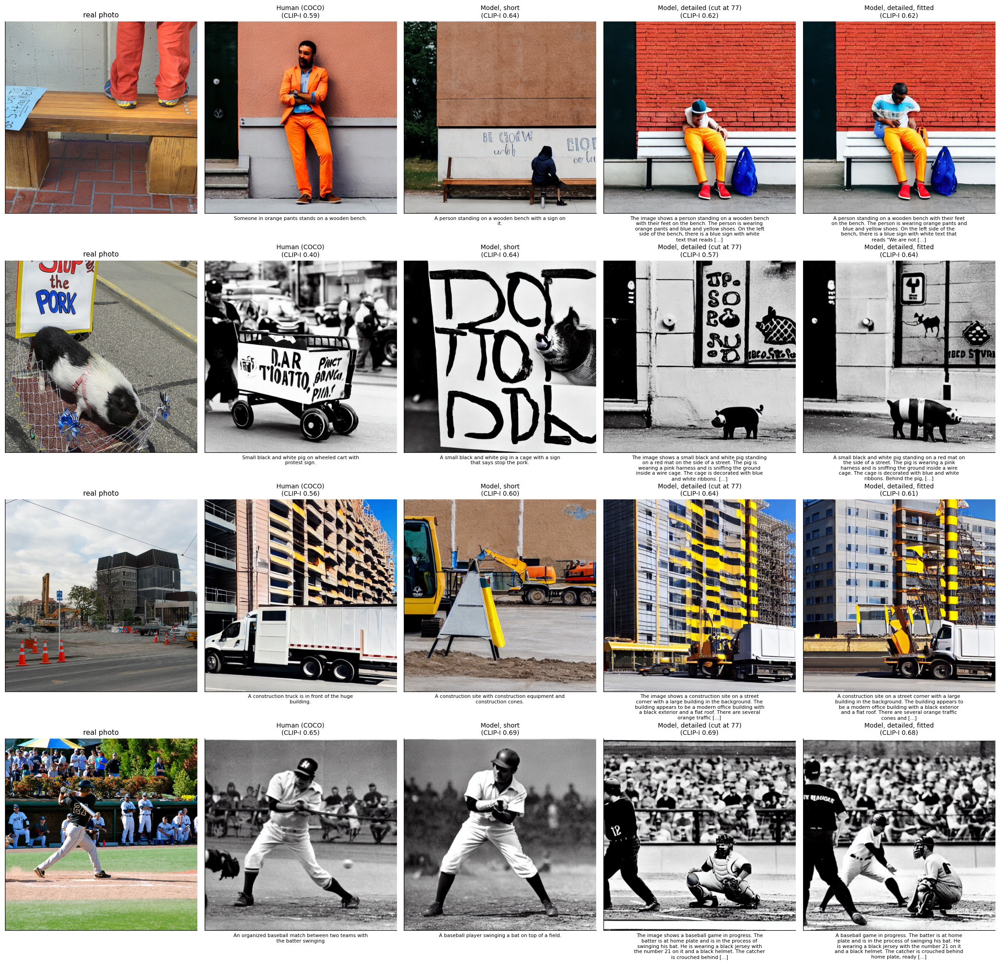

In [14]:
# examples: the real photo and the image each caption produced (same seed)
# four photos chosen to illustrate the findings (a person on a bench, a sign, a construction site, a sports scene)
EXAMPLES = ["Someone in orange pants stands on a wooden bench.",
            "Small black and white pig on wheeled cart with protest sign.",
            "A construction truck is in front of the huge building.",
            "An organized baseball match between two teams with the batter swinging"]
show = sub.set_index("human").reindex(EXAMPLES).dropna(subset=["caption_idx"]).reset_index()
show["caption_idx"] = show.caption_idx.astype(int)
fig, ax = plt.subplots(len(show), 5, figsize=(20, 4.8 * len(show)))
for i, r in enumerate(show.itertuples()):
    ax[i, 0].imshow(Image.open(r.real_path)); ax[i, 0].set_title("real photo", fontsize=10)
    for j, s in enumerate(SOURCES):
        row = gen[(gen.caption_idx == r.caption_idx) & (gen.source == s) & (gen.seed == CFG["seeds"][0])].iloc[0]
        ax[i, j + 1].imshow(Image.open(row.path))
        ax[i, j + 1].set_title(f"{LABEL[s]}\n(CLIP-I {row.clip_i:.2f})", fontsize=9)
        ax[i, j + 1].set_xlabel(textwrap.fill(textwrap.shorten(getattr(r, s), 230), 52), fontsize=7)
for a in ax.flat:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); savefig("03_examples"); plt.show()

## 9. How to read the results

* **Fitted detectably better than cut-off detailed** (on CLIP-I or object recall): the cut-off was holding the detailed captions back (explanation A). Writing prompts that put the important content inside 77 tokens helps, and a text encoder that reads longer text (such as T5) could help more.
* **No detectable gain for fitted over cut-off detailed, or over human**: with this sample, longer captions gave no detectable gain, which points to explanation B (Stable Diffusion cannot use the extra detail even when it reads it). It is not proof that there is no gain at all: the upper end of each 95% range is the largest gain still possible. Confirm with `n_recap = 300` and `seeds = (0, 1)`.
* **Named-object recall** is the cleanest test of the model: a low value means objects that were asked for and read are still not drawn, whatever the caption.
* **The "part SD reads" column** in Section 6 shows how much of the scene each caption actually communicates. If the fitted captions name many more of the photo's objects within 75 tokens than the cut-off ones, yet the images do not improve, that is the clearest sign of explanation B.
* With 100 photos and one seed, an interval that crosses zero means "not shown", not "no effect". `n_recap = 300` and `seeds = (0, 1)` narrow the intervals.

## 10. Summary

In [15]:
summary = {"captioner": CAPTIONER, "photos": len(sub), "seeds": list(CFG["seeds"]),
           "caption_stats": cap_table.round(4).to_dict("index"),
           "image_metrics": table.round(4).to_dict("index"),
           "differences": delta_df.round(4).to_dict("records"),
           "fitting": {"budget_tokens": BUDGET, "mean_sentences": float(sub.sentences.mean()),
                       "mean_sentences_kept": float(sub.sentences_kept.mean())},
           "detector_recall_on_real_photos": round(detector_ceiling, 4),
           "blacked_out_images_excluded": blacked.groupby("source").size().reindex(SOURCES, fill_value=0).to_dict(),
           "named_read_missing": {"objects": int(len(missing_df)), "trustworthy": int(missing_df.detector_found_in_real_photo.sum()),
                                  "file": str(OUT / "named_read_missing.csv")},
           "generation": {"steps": CFG["steps"], "guidance": CFG["guidance"], "scheduler": "PNDM", "model": CFG["sd_id"]}}
json.dump(summary, open(OUT / "recaptioning_v2_summary.json", "w"), indent=2, default=str)
print(json.dumps(summary, indent=2, default=str)[:3500])
print("\nSaved to", OUT)
for p in sorted(OUT.rglob("*")):
    if p.is_file():
        print("  ", p.relative_to(OUT))

{
  "captioner": "Florence-2-large",
  "photos": 100,
  "seeds": [
    0
  ],
  "caption_stats": {
    "Human (COCO)": {
      "words": 10.0,
      "clip_tokens": 13.0,
      "over_77_share": 0.0,
      "tokens_cut_mean": 0.0,
      "objects_named": 1.26,
      "photo_objects_named": 0.6447,
      "photo_objects_named_readable": 0.6447,
      "photo_objects_named_no_person": 0.547,
      "photo_objects_named_readable_no_person": 0.547,
      "named_not_labelled": 0.0417
    },
    "Model, short": {
      "words": 11.0,
      "clip_tokens": 14.0,
      "over_77_share": 0.0,
      "tokens_cut_mean": 0.0,
      "objects_named": 1.43,
      "photo_objects_named": 0.6924,
      "photo_objects_named_readable": 0.6924,
      "photo_objects_named_no_person": 0.6215,
      "photo_objects_named_readable_no_person": 0.6215,
      "named_not_labelled": 0.0525
    },
    "Model, detailed (cut at 77)": {
      "words": 84.0,
      "clip_tokens": 96.5,
      "over_77_share": 0.94,
      "tokens_cut_m